In [ ]:
from pathlib import Path
import torch
from data_processing.data_preprocessing import (
    read_image_as_tensor,
    get_contrastive_transforms,
)

# 1. Đường dẫn tới 1 ảnh bất kỳ trong dataset
img_path = Path("dataset/rvl-cdip/images/imagesq/q/o/c/qoc54c00/80035521.tif")

# 2. Đọc ảnh thành Tensor gốc (3, H, W) kiểu uint8
img_tensor = read_image_as_tensor(img_path)
print("Shape ảnh gốc:", img_tensor.shape)  # Ví dụ: torch.Size([3, 1000, 754])
print("Dtype:", img_tensor.dtype)          # torch.uint8

# 3. Thử nghiệm hàm tăng cường dữ liệu (Augmentation)
augment = get_contrastive_transforms(max_shear=10.0, noise_std=0, p_erase=0.2)

# Sinh 2 góc nhìn (2 views) khác nhau từ cùng 1 ảnh
view1 = augment(img_tensor)
view2 = augment(img_tensor)
print("View 1 shape:", view1.shape)
print("View 2 shape:", view2.shape)
print("Sai khác pixel:", torch.abs(view1.float() - view2.float()).mean().item())

Shape ảnh gốc: torch.Size([3, 1000, 754])
Dtype: torch.uint8
View 1 shape: torch.Size([3, 1000, 754])
View 2 shape: torch.Size([3, 1000, 754])
Sai khác pixel: 57.64910888671875


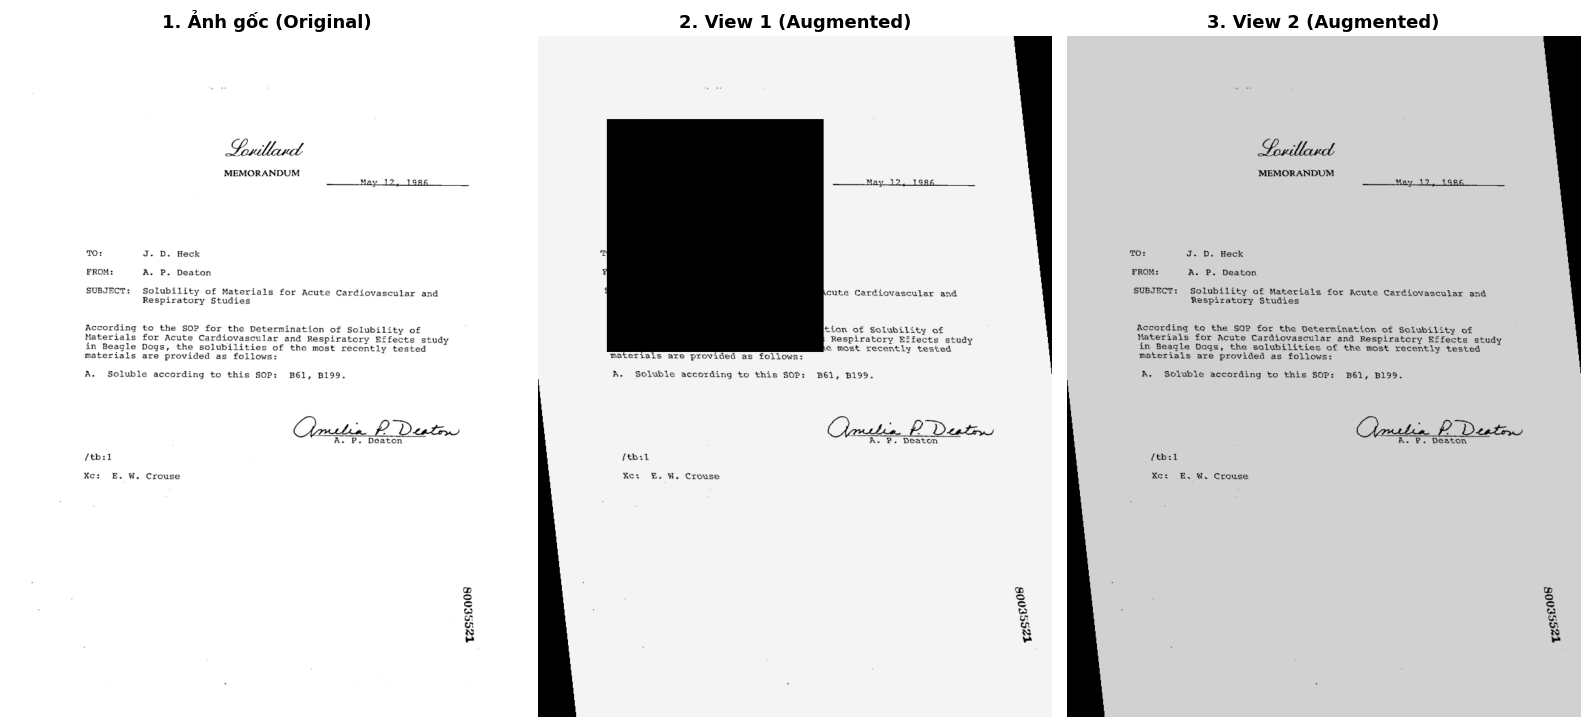

In [24]:
import matplotlib.pyplot as plt
from torchvision.transforms.functional import to_pil_image

# 4. Hiển thị so sánh: Ảnh gốc - View 1 - View 2
fig, axes = plt.subplots(1, 3, figsize=(16, 8))

# Chuyển Tensor (3, H, W) uint8 sang ảnh PIL để hiển thị
axes[0].imshow(to_pil_image(img_tensor))
axes[0].set_title("1. Ảnh gốc (Original)", fontsize=13, fontweight="bold")
axes[0].axis("off")

axes[1].imshow(to_pil_image(view1))
axes[1].set_title("2. View 1 (Augmented)", fontsize=13, fontweight="bold")
axes[1].axis("off")

axes[2].imshow(to_pil_image(view2))
axes[2].set_title("3. View 2 (Augmented)", fontsize=13, fontweight="bold")
axes[2].axis("off")

plt.tight_layout()
plt.show()

In [25]:
from pathlib import Path
from transformers import AutoProcessor
from utils.dataloader import build_dataloader
from data_processing.data_preprocessing import get_transforms

# Khởi tạo processor chuẩn LayoutLMv3 (resize về 224x224 và chuẩn hóa)
processor = AutoProcessor.from_pretrained("configs/layoutlmv3-base", apply_ocr=False)

# Tạo DataLoader chế độ Contrastive (batch_size=2)
loader = build_dataloader(
    data_dir=Path("dataset/rvl-cdip"),
    split="train",
    processor=processor,
    batch_size=2,
    transform=get_contrastive_transforms(),
    is_contrastive=True,
    num_workers=0,
)

# Lấy thử 1 batch đầu tiên ra xem
batch = next(iter(loader))

print("Keys trong batch:", batch.keys())
# Output: dict_keys(['view1', 'view2', 'labels', 'image_paths'])

print("Shape View 1:", batch["view1"]["pixel_values"].shape)  # [2, 3, 224, 224]
print("Shape View 2:", batch["view2"]["pixel_values"].shape)  # [2, 3, 224, 224]
print("Labels batch:", batch["labels"])                      # tensor([10, 15])

Keys trong batch: dict_keys(['view1', 'view2', 'labels', 'image_paths'])
Shape View 1: torch.Size([2, 3, 224, 224])
Shape View 2: torch.Size([2, 3, 224, 224])
Labels batch: tensor([11, 12])


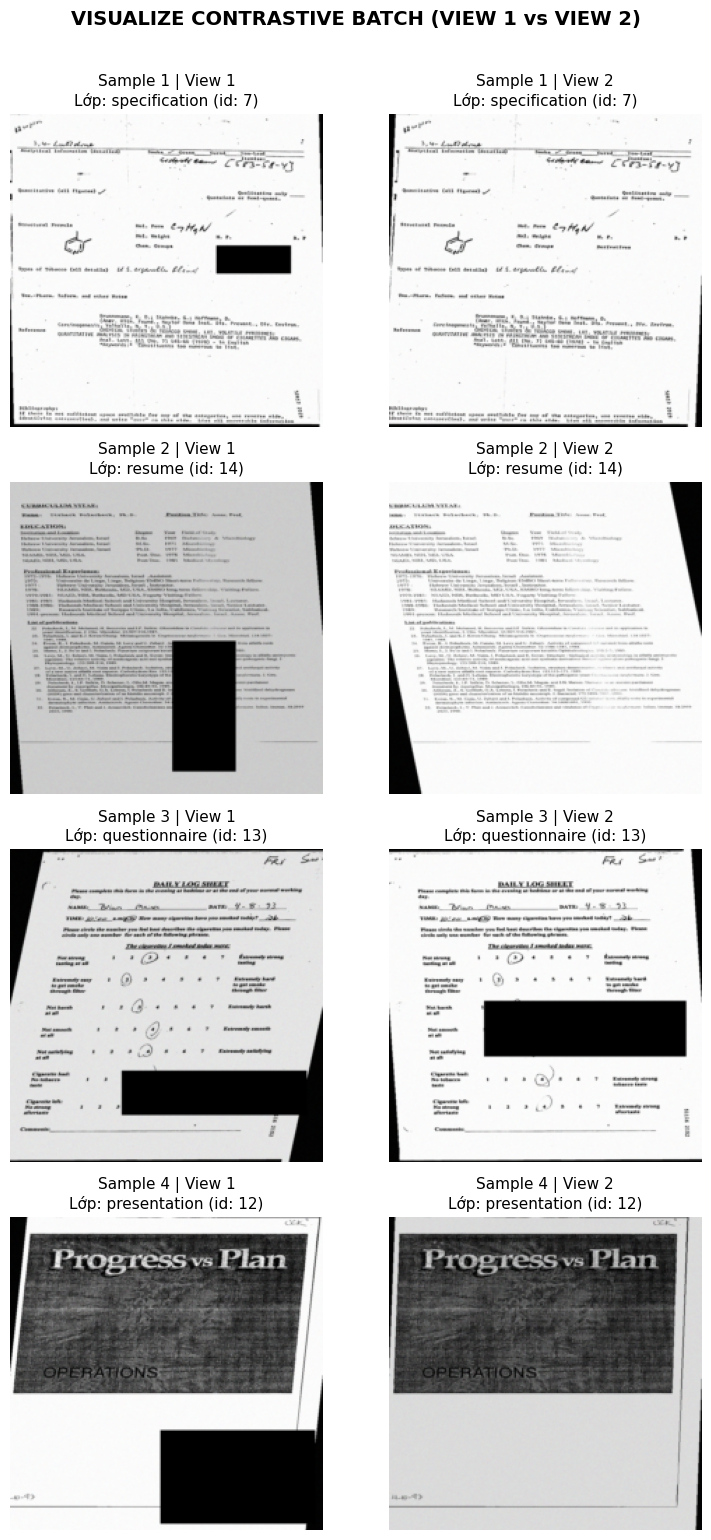

In [26]:
from pathlib import Path
import matplotlib.pyplot as plt
import torch
from transformers import AutoProcessor

from data_processing.data_preprocessing import (
    RVLCDIPDataset,
    get_transforms,
)
from utils.dataloader import build_dataloader


def to_displayable(tensor: torch.Tensor):
    """Chuyển tensor (3, H, W) về định dạng (H, W, 3) trong dải [0, 1] để vẽ."""
    t = tensor.detach().cpu().float()
    if t.min() < 0:  # Nếu ảnh đã qua processor LayoutLMv3 (dải [-1, 1])
        t = (t * 0.5 + 0.5).clamp(0, 1)
    elif t.max() > 1.0:  # Nếu là tensor gốc uint8 [0, 255]
        t = (t / 255.0).clamp(0, 1)
    return t.permute(1, 2, 0).numpy()


# ==============================================================================
# 1. KHỞI TẠO DATALOADER (Ví dụ batch_size = 4)
# ==============================================================================
data_dir = Path("dataset/rvl-cdip")
processor = AutoProcessor.from_pretrained("configs/layoutlmv3-base", apply_ocr=False)

# Mẹo: Đặt max_samples=100 khi test trên Google Drive để nạp tức thì trong 0.1s
loader = build_dataloader(
    data_dir=data_dir,
    split="train",
    processor=processor,
    batch_size=4,
    transform=get_contrastive_transforms(max_shear=10.0, noise_std=8.0, p_erase=0.5),
    is_contrastive=True,  # True: 2 views | False: single view
    num_workers=0,
    max_samples=100,
)

# Lấy 1 batch ra để visualize
batch = next(iter(loader))
labels = batch["labels"]
batch_size = len(labels)


# ==============================================================================
# 2. VẼ VISUALIZE CẢ BATCH
# ==============================================================================
if "view1" in batch and "view2" in batch:
    # ------------------ Chế độ Contrastive SupCon (2 Views) ------------------
    v1_tensors = batch["view1"]["pixel_values"]
    v2_tensors = batch["view2"]["pixel_values"]

    fig, axes = plt.subplots(batch_size, 2, figsize=(8, 3.8 * batch_size))
    if batch_size == 1:
        axes = axes.reshape(1, 2)

    for i in range(batch_size):
        label_id = labels[i].item()
        label_name = RVLCDIPDataset.LABEL_NAMES[label_id]

        # Vẽ View 1
        axes[i, 0].imshow(to_displayable(v1_tensors[i]))
        axes[i, 0].set_title(f"Sample {i+1} | View 1\nLớp: {label_name} (id: {label_id})", fontsize=11)
        axes[i, 0].axis("off")

        # Vẽ View 2
        axes[i, 1].imshow(to_displayable(v2_tensors[i]))
        axes[i, 1].set_title(f"Sample {i+1} | View 2\nLớp: {label_name} (id: {label_id})", fontsize=11)
        axes[i, 1].axis("off")

    plt.suptitle("VISUALIZE CONTRASTIVE BATCH (VIEW 1 vs VIEW 2)", fontsize=14, fontweight="bold", y=1.01)
    plt.tight_layout()
    plt.show()

else:
    # ------------------ Chế độ Single-view ------------------
    images = batch["pixel_values"]
    fig, axes = plt.subplots(1, batch_size, figsize=(4 * batch_size, 4))
    if batch_size == 1:
        axes = [axes]

    for i in range(batch_size):
        label_id = labels[i].item()
        label_name = RVLCDIPDataset.LABEL_NAMES[label_id]

        axes[i].imshow(to_displayable(images[i]))
        axes[i].set_title(f"Mẫu {i+1}: {label_name}\n(ID: {label_id})", fontsize=11)
        axes[i].axis("off")

    plt.suptitle("VISUALIZE SINGLE-VIEW BATCH", fontsize=14, fontweight="bold", y=1.05)
    plt.tight_layout()
    plt.show()